<a href="https://colab.research.google.com/github/DalilaGallegos/Portafolio-Diplomado-en-Python-Gallegos-Jimenez-Yajaira-Dalila/blob/main/02_Clasificacion_Completa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DIPLOMADO: PROGRAMACIÓN EN PYTHON PARA LA WEB Y EL ANÁLISIS DE DATOS

## Portafolio de Evidencias de Aprendizaje

### Notebook 2. Proyecto completo de clasificación mediante CRISP-DM

**Proyecto:** Predicción del abandono de clientes en una empresa de telecomunicaciones  
**Conjunto de datos:** Telco Customer Churn  
**Metodología:** CRISP-DM  
**Tipo de problema:** Clasificación binaria  
**Algoritmo principal:** Regresión Logística  
**Variable objetivo:** `Churn`

**Nombre del estudiante:** Yajaira Dalila Gallegos Jiménez

# Introducción

El abandono de clientes, conocido como *customer churn*, representa un problema importante para las empresas que ofrecen servicios mediante contratos o suscripciones. Cuando un cliente decide cancelar los servicios que mantiene con una compañía se produce una pérdida que puede afectar tanto la cantidad de usuarios como los ingresos de la organización.

La ciencia de datos y el aprendizaje automático permiten analizar información histórica para identificar patrones y desarrollar modelos capaces de estimar la probabilidad de que determinados clientes presenten comportamientos similares a los observados anteriormente.

En este proyecto se utilizará el conjunto de datos **Telco Customer Churn**, que contiene información demográfica, servicios contratados, características comerciales y datos de facturación de clientes de una empresa de telecomunicaciones.

A diferencia del primer notebook, cuyo alcance se limitó al análisis exploratorio, en esta actividad se desarrollarán las cinco fases de trabajo de CRISP-DM estudiadas durante el diplomado: **Comprensión del negocio, Comprensión de los datos, Preparación de los datos, Modelado y Evaluación**.

El objetivo será construir un modelo de clasificación capaz de estimar si un cliente pertenece a la categoría de quienes abandonaron o permanecieron en la compañía, utilizando para ello el algoritmo de Regresión Logística.

# Objetivo

Desarrollar un modelo de aprendizaje automático para clasificar el abandono de clientes de una empresa de telecomunicaciones, aplicando las cinco fases de trabajo de la metodología CRISP-DM.

Para ello se analizará y preparará el conjunto de datos **Telco Customer Churn**, se entrenará un modelo de Regresión Logística y posteriormente se evaluará su desempeño mediante métricas de clasificación como Accuracy, Precision, Recall y F1-score, además de una matriz de confusión.

# 1. Comprensión del negocio

## 1.1 Descripción del problema

Una empresa de telecomunicaciones puede ofrecer diferentes servicios, como telefonía, Internet, seguridad en línea, soporte técnico y entretenimiento. Sin embargo, algunos clientes pueden decidir cancelar estos servicios y abandonar la compañía.

Este comportamiento se conoce como **Churn**.

El problema que se pretende abordar consiste en utilizar información histórica sobre los clientes para construir un modelo capaz de identificar patrones asociados con el abandono y clasificar nuevos registros en una de dos categorías:

- Cliente que permanece en la compañía.
- Cliente que abandona la compañía.

Por lo tanto, se trata de un problema de **clasificación binaria**.

## 1.2 Importancia del problema

El abandono de clientes puede representar un problema para una empresa porque implica la pérdida de usuarios que anteriormente utilizaban sus servicios.

Contar con información que permita identificar clientes con características similares a quienes anteriormente abandonaron la compañía podría ayudar a orientar acciones de atención, seguimiento o retención.

Un modelo de aprendizaje automático no puede determinar con certeza qué decisión tomará una persona, pero sí puede aprender patrones presentes en información histórica y generar una estimación basada en ellos.

Por esta razón, el modelo desarrollado debe considerarse como una herramienta de apoyo para el análisis y no como un sistema que determina automáticamente las decisiones futuras de los clientes.

## 1.3 Objetivo del proyecto

Construir un modelo de clasificación mediante Regresión Logística que utilice las características disponibles de los clientes para estimar si pertenecen a la categoría de clientes que abandonan o permanecen en la empresa de telecomunicaciones.

## 1.4 Variable objetivo

La variable objetivo del proyecto es `Churn`.

Esta variable presenta dos categorías:

- `No`: el cliente permaneció en la compañía.
- `Yes`: el cliente abandonó la compañía.

Para el desarrollo del modelo estas categorías serán posteriormente transformadas a valores numéricos:

- `0`: No abandonó.
- `1`: Sí abandonó.

Debido a que únicamente existen dos posibles resultados, el problema corresponde a una **clasificación binaria**.

## 1.5 Resultados esperados

Se espera obtener un modelo que, a partir de las características de un cliente, pueda generar una clasificación relacionada con su comportamiento de abandono.

Además de obtener las predicciones, el modelo será evaluado utilizando diferentes métricas con la finalidad de conocer no solamente cuántas clasificaciones realiza correctamente, sino también qué tan bien logra identificar específicamente a los clientes que abandonaron la compañía.

Los resultados esperados incluirán:

- Predicciones sobre clientes que no fueron utilizados durante el entrenamiento.
- Accuracy.
- Precision.
- Recall.
- F1-score.
- Matriz de confusión.
- Análisis de los errores del modelo.

# 2. Comprensión de los datos

En esta fase se realizará una exploración del conjunto de datos para conocer sus dimensiones, variables, tipos de datos, calidad de la información y distribución de la variable objetivo.

Esta etapa permitirá identificar las transformaciones que serán necesarias antes de entrenar el modelo.

## 2.1 Origen del conjunto de datos

El conjunto de datos utilizado es **Telco Customer Churn**, disponible públicamente en la plataforma Kaggle.

El archivo utilizado se denomina:

`WA_Fn-UseC_-Telco-Customer-Churn.csv`

Cada fila representa a un cliente y las columnas contienen información relacionada con sus características personales, servicios contratados, tipo de contrato, facturación y comportamiento de abandono.

## 2.2 Importación de librerías

Para desarrollar el proyecto se utilizarán diferentes bibliotecas de Python:

- **Pandas:** manipulación y análisis de datos.
- **NumPy:** operaciones numéricas.
- **Matplotlib:** creación de gráficas.
- **Seaborn:** visualización estadística.
- **Scikit-learn:** preparación de datos, construcción del modelo y evaluación.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2.3 Conexión con Google Drive

El archivo CSV se encuentra almacenado en Google Drive, por lo que se conectará Google Colab con Drive para poder acceder al conjunto de datos.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 2.4 Carga del conjunto de datos

El conjunto de datos será importado mediante `read_csv()` de Pandas y almacenado en un DataFrame llamado `df`.

In [3]:
ruta = "/content/drive/MyDrive/Diplomado/Proyecto: Redes Neuronales/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(ruta)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


La visualización inicial permite comprobar que el conjunto de datos fue cargado correctamente.

Se observan variables relacionadas con características personales de los clientes, servicios contratados, información comercial y datos de facturación.

## 2.5 Dimensiones del conjunto de datos

In [4]:
print("Número de registros:", df.shape[0])
print("Número de variables:", df.shape[1])

Número de registros: 7043
Número de variables: 21


El conjunto de datos contiene **7,043 registros y 21 variables**.

Cada registro representa a un cliente y cada columna corresponde a una característica asociada con dicho cliente.

## 2.6 Identificación de las variables

In [5]:
for i, columna in enumerate(df.columns, start=1):
    print(f"{i}. {columna}")

1. customerID
2. gender
3. SeniorCitizen
4. Partner
5. Dependents
6. tenure
7. PhoneService
8. MultipleLines
9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


## 2.7 Tipos de datos

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Se observa que el conjunto de datos contiene variables numéricas y categóricas.

Una característica importante es que `TotalCharges`, aunque representa un valor monetario, aparece almacenada como tipo `object`.

Esto indica que existe algún contenido dentro de esta columna que impide que Pandas la reconozca automáticamente como una variable numérica.

Esta situación deberá ser corregida durante la fase de preparación de los datos.

## 2.8 Estadísticas descriptivas

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [8]:
df.describe(include="object").T

,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


Las estadísticas descriptivas permiten conocer el comportamiento general de las variables.

Las variables numéricas presentan diferentes escalas. Por ejemplo, `tenure` se encuentra expresada en meses, mientras que `MonthlyCharges` representa cantidades monetarias.

También se observa que la mayoría de las variables categóricas contienen un número reducido de categorías, lo que permitirá posteriormente transformarlas mediante técnicas de codificación.

## 2.9 Valores faltantes

In [9]:
print("Valores nulos detectados directamente:")
df.isnull().sum()

Valores nulos detectados directamente:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [10]:
espacios_total_charges = (
    df["TotalCharges"].str.strip() == ""
).sum()

print(
    "Espacios en blanco encontrados en TotalCharges:",
    espacios_total_charges
)

Espacios en blanco encontrados en TotalCharges: 11


Aunque `isnull()` no detectó inicialmente valores nulos, una revisión específica de `TotalCharges` permitió identificar **11 registros con espacios en blanco**.

Estos valores explican por qué la columna está almacenada como texto.

Durante la etapa de preparación se deberá convertir esta variable a formato numérico y decidir cómo tratar los registros en los que no existe un valor válido.

## 2.10 Registros duplicados

In [11]:
print(
    "Registros completamente duplicados:",
    df.duplicated().sum()
)

print(
    "Identificadores únicos:",
    df["customerID"].nunique()
)

Registros completamente duplicados: 0
Identificadores únicos: 7043


No se identificaron registros completamente duplicados.

Además, `customerID` contiene un identificador diferente para cada cliente, lo que confirma que funciona como una variable de identificación y no como una característica que describa su comportamiento.

Por esta razón, `customerID` será eliminada antes del entrenamiento del modelo.

## 2.11 Distribución de la variable objetivo

In [12]:
conteo_churn = df["Churn"].value_counts()

porcentaje_churn = (
    df["Churn"].value_counts(normalize=True) * 100
)

print("Cantidad:")
print(conteo_churn)

print("\nPorcentaje:")
print(porcentaje_churn.round(2))

Cantidad:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Porcentaje:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


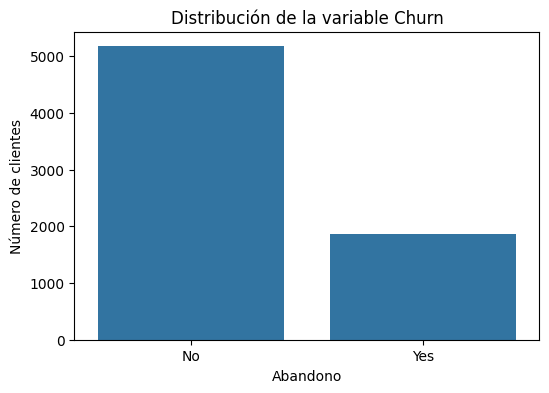

In [13]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Distribución de la variable Churn")
plt.xlabel("Abandono")
plt.ylabel("Número de clientes")

plt.show()

La variable objetivo presenta un desbalance moderado.

Aproximadamente el **73.46 %** de los clientes permanecieron en la compañía, mientras que el **26.54 %** abandonaron el servicio.

Esto deberá considerarse durante la evaluación del modelo. Utilizar únicamente Accuracy podría proporcionar una visión incompleta de su funcionamiento, por lo que también se evaluarán Precision, Recall y F1-score.

# 3. Preparación de los datos

En esta fase se realizarán las transformaciones necesarias para que el conjunto de datos pueda ser utilizado por el algoritmo de aprendizaje automático.

Las principales actividades serán:

1. Crear una copia del conjunto original.
2. Corregir la variable `TotalCharges`.
3. Tratar valores faltantes.
4. Revisar registros duplicados.
5. Eliminar variables que no aportan información útil al modelo.
6. Codificar la variable objetivo.
7. Separar variables predictoras y variable objetivo.
8. Dividir los datos en entrenamiento y prueba.
9. Codificar variables categóricas.
10. Estandarizar variables numéricas.

## 3.1 Creación de una copia

Se creará una copia del DataFrame original para conservar intactos los datos cargados inicialmente.

In [14]:
df_modelo = df.copy()

print("Dimensiones iniciales:", df_modelo.shape)

Dimensiones iniciales: (7043, 21)


## 3.2 Conversión de `TotalCharges`

La variable `TotalCharges` representa una cantidad monetaria y debe tratarse como una variable numérica.

Se utilizará `pd.to_numeric()` con `errors="coerce"` para convertir los valores válidos a números y transformar los espacios en blanco en valores `NaN`.

In [15]:
df_modelo["TotalCharges"] = pd.to_numeric(
    df_modelo["TotalCharges"],
    errors="coerce"
)

print(
    "Valores faltantes en TotalCharges después de la conversión:",
    df_modelo["TotalCharges"].isnull().sum()
)

Valores faltantes en TotalCharges después de la conversión: 11


Después de la conversión aparecen **11 valores faltantes**.

Debido a que representan una cantidad muy pequeña respecto al total de registros y no se conoce con certeza cuál debería ser el valor correcto de `TotalCharges`, se eliminarán estos registros en lugar de asignarles un valor estimado.

Esta decisión evita introducir información artificial en los datos.

In [16]:
porcentaje_faltantes = (
    df_modelo["TotalCharges"].isnull().sum()
    / len(df_modelo)
    * 100
)

print(
    f"Porcentaje de registros afectados: "
    f"{porcentaje_faltantes:.4f}%"
)

df_modelo = df_modelo.dropna(
    subset=["TotalCharges"]
).copy()

print(
    "Dimensiones después de eliminar los registros:",
    df_modelo.shape
)

Porcentaje de registros afectados: 0.1562%
Dimensiones después de eliminar los registros: (7032, 21)


Después de eliminar los 11 registros sin un valor válido de `TotalCharges`, el conjunto de datos queda formado por **7,032 registros**.


## 3.3 Tratamiento de registros duplicados

Aunque durante la comprensión de los datos no se encontraron registros duplicados, se volverá a comprobar esta situación antes del modelado.

In [17]:
duplicados = df_modelo.duplicated().sum()

print("Registros duplicados:", duplicados)

df_modelo = df_modelo.drop_duplicates().copy()

Registros duplicados: 0


## 3.4 Eliminación de `customerID`

La variable `customerID` únicamente identifica a cada cliente y no describe una característica relacionada con su comportamiento.

Además, prácticamente cada registro posee un identificador diferente. Incluir esta variable podría agregar información sin significado predictivo para el problema.

Por esta razón será eliminada antes de entrenar el modelo.

In [18]:
df_modelo = df_modelo.drop(
    columns=["customerID"]
)

df_modelo.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3.5 Codificación de la variable objetivo

La variable `Churn` contiene originalmente las categorías `No` y `Yes`.

Para utilizarla en el modelo se transformará de la siguiente manera:

- `No` → 0
- `Yes` → 1

In [19]:
df_modelo["Churn"] = df_modelo["Churn"].map({
    "No": 0,
    "Yes": 1
})

df_modelo["Churn"].value_counts()

,count
Churn,
0,5163
1,1869


## 3.6 Separación de variables predictoras y variable objetivo

Las variables utilizadas para realizar las predicciones se almacenarán en `X`.

La variable que se desea predecir se almacenará en `y`.

In [20]:
X = df_modelo.drop(
    columns=["Churn"]
)

y = df_modelo["Churn"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (7032, 19)
Dimensiones de y: (7032,)


## 3.7 División en entrenamiento y prueba

El conjunto de datos se dividirá de la siguiente manera:

- **80 %:** entrenamiento.
- **20 %:** prueba.

El conjunto de entrenamiento será utilizado para que el algoritmo aprenda los patrones existentes.

El conjunto de prueba permanecerá separado y será utilizado al final para conocer el desempeño del modelo con registros que no participaron en su entrenamiento.

Se utilizará `stratify=y` para conservar aproximadamente la misma proporción de clientes que abandonaron y permanecieron en ambos conjuntos.

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5625, 19)
X_test: (1407, 19)
y_train: (5625,)
y_test: (1407,)


In [22]:
print("Distribución en entrenamiento:")

print(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
)

print("\nDistribución en prueba:")

print(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
)

Distribución en entrenamiento:
Churn
0    73.42
1    26.58
Name: proportion, dtype: float64

Distribución en prueba:
Churn
0    73.42
1    26.58
Name: proportion, dtype: float64


Las proporciones de ambas clases se mantienen de manera similar en los conjuntos de entrenamiento y prueba gracias al uso de una división estratificada.

## 3.8 Identificación de variables numéricas y categóricas

Las variables requieren diferentes tratamientos antes de ser utilizadas por la Regresión Logística.

Las variables numéricas serán estandarizadas mediante `StandardScaler`.

Las variables categóricas serán transformadas a valores numéricos mediante `OneHotEncoder`.

In [23]:
columnas_numericas = (
    X_train
    .select_dtypes(include=["int64", "float64"])
    .columns
    .tolist()
)

columnas_categoricas = (
    X_train
    .select_dtypes(include=["object"])
    .columns
    .tolist()
)

print("Variables numéricas:")
print(columnas_numericas)

print("\nVariables categóricas:")
print(columnas_categoricas)

Variables numéricas:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables categóricas:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 3.9 Preprocesamiento

Para realizar las transformaciones se utilizará `ColumnTransformer`.

Las variables numéricas se procesarán mediante `StandardScaler`, que modifica su escala para que tengan valores comparables.

Las variables categóricas se transformarán mediante `OneHotEncoder`, creando columnas numéricas que representan sus diferentes categorías.

El parámetro `handle_unknown="ignore"` permitirá que el proceso continúe correctamente si durante la predicción aparece alguna categoría que no estuvo presente en los datos utilizados para ajustar el codificador.

Las transformaciones se integrarán posteriormente dentro de un Pipeline para que sean ajustadas utilizando únicamente los datos de entrenamiento. Esto ayuda a evitar utilizar información del conjunto de prueba durante el aprendizaje.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            columnas_numericas
        ),
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            columnas_categoricas
        )
    ]
)

preprocesador

ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('categoricas',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])

# 4. Modelado

## 4.1 Algoritmo seleccionado: Regresión Logística

Para resolver el problema se utilizará **Regresión Logística**.

A pesar de incluir la palabra "regresión" en su nombre, este algoritmo se utiliza ampliamente para problemas de clasificación.

En un problema binario, la Regresión Logística estima la probabilidad de que un registro pertenezca a la clase positiva.

En este proyecto:

- Clase 0 = cliente que no abandonó.
- Clase 1 = cliente que abandonó.

El modelo generará una probabilidad entre 0 y 1. A partir de un umbral de clasificación, normalmente 0.5, esa probabilidad se convierte en una de las dos clases.

Se eligió este algoritmo porque:

- Es adecuado para clasificación binaria.
- Puede trabajar con múltiples variables.
- Permite obtener probabilidades de clasificación.
- Es un modelo ampliamente utilizado como punto de referencia en problemas de clasificación.
- Su funcionamiento es relativamente sencillo de interpretar.

## 4.2 Construcción del Pipeline

El preprocesamiento y el modelo se integrarán en un único Pipeline.

Esto permitirá que durante `fit()` primero se realicen automáticamente las transformaciones necesarias sobre los datos de entrenamiento y posteriormente se entrene la Regresión Logística.

Durante `predict()`, las mismas transformaciones aprendidas se aplicarán a los nuevos datos antes de generar las predicciones.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

modelo = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador
        ),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

modelo

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('clasificador', LogisticRegression(max_iter=1000))])

## 4.3 Entrenamiento del modelo

El modelo será entrenado utilizando exclusivamente los datos pertenecientes al conjunto de entrenamiento.

In [26]:
modelo.fit(
    X_train,
    y_train
)

print("Entrenamiento finalizado correctamente.")

Entrenamiento finalizado correctamente.


## 4.4 Predicciones sobre el conjunto de prueba

Después del entrenamiento se utilizarán los registros del conjunto de prueba.

Estos clientes no participaron en el ajuste del modelo, por lo que permiten evaluar su capacidad para trabajar con información que no utilizó directamente durante el aprendizaje.

In [27]:
y_pred = modelo.predict(
    X_test
)

y_prob = modelo.predict_proba(
    X_test
)[:, 1]

print(
    "Número de predicciones realizadas:",
    len(y_pred)
)

Número de predicciones realizadas: 1407


Además de la clasificación final, `predict_proba()` permite obtener la probabilidad estimada de pertenecer a la clase positiva, que en este proyecto corresponde al abandono del servicio.

In [28]:
resultados_prediccion = pd.DataFrame({
    "Valor_real": y_test.values,
    "Prediccion": y_pred,
    "Probabilidad_Churn": y_prob
})

resultados_prediccion.head(10)

,Valor_real,Prediccion,Probabilidad_Churn
0,0,0,0.017513
1,0,1,0.591921
2,0,0,0.004821
3,1,0,0.201652
4,0,0,0.101501
5,1,0,0.471845
6,0,0,0.026518
7,0,0,0.165431
8,1,1,0.679600
9,0,0,0.015525


En la tabla:

- `Valor_real` representa lo que ocurrió realmente.
- `Prediccion` corresponde a la clasificación realizada por el modelo.
- `Probabilidad_Churn` representa la probabilidad estimada de que el cliente pertenezca a la clase de abandono.

La probabilidad no debe interpretarse como una certeza sobre el comportamiento futuro de una persona, sino como el resultado del patrón estadístico aprendido por el modelo.

# 5. Evaluación

El desempeño del modelo se analizará utilizando diferentes métricas.

No se utilizará únicamente Accuracy debido al desbalance existente entre las categorías de `Churn`.

Las métricas principales serán:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** de los clientes clasificados como abandono, cuántos realmente abandonaron.
- **Recall:** de los clientes que realmente abandonaron, cuántos fueron identificados correctamente.
- **F1-score:** combina Precision y Recall en una sola medida.

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print(f"Accuracy:  {accuracy:.4f} ({accuracy:.2%})")
print(f"Precision: {precision:.4f} ({precision:.2%})")
print(f"Recall:    {recall:.4f} ({recall:.2%})")
print(f"F1-score:  {f1:.4f} ({f1:.2%})")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.8038 (80.38%)
Precision: 0.6485 (64.85%)
Recall:    0.5722 (57.22%)
F1-score:  0.6080 (60.80%)
ROC-AUC:   0.8359


In [30]:
metricas = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Valor": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

metricas["Valor"] = metricas["Valor"].round(4)

metricas

,Métrica,Valor
0,Accuracy,0.8038
1,Precision,0.6485
2,Recall,0.5722
3,F1-score,0.6080
4,ROC-AUC,0.8359


## 5.1 Interpretación de las métricas

Las métricas permiten analizar diferentes aspectos del funcionamiento del modelo.

**Accuracy** indica qué proporción total de clientes fue clasificada correctamente.

**Precision** muestra qué proporción de los clientes que el modelo identificó como abandono realmente pertenecía a esa categoría.

**Recall** permite conocer qué proporción de todos los clientes que realmente abandonaron fue identificada correctamente. En un problema de abandono de clientes esta métrica resulta especialmente relevante, porque un Recall bajo significaría que una cantidad importante de clientes que abandonaron no fue detectada por el modelo.

**F1-score** proporciona una medida que considera simultáneamente Precision y Recall.

Finalmente, **ROC-AUC** evalúa la capacidad del modelo para diferenciar entre ambas clases utilizando las probabilidades generadas.

## 5.2 Comparación con una estrategia básica

Debido a que la mayoría de los clientes pertenecen a la categoría `No`, es conveniente conocer qué Accuracy se obtendría simplemente prediciendo siempre la clase mayoritaria.

Esto proporciona un punto de referencia para interpretar el desempeño del modelo.

In [31]:
accuracy_base = (
    y_test
    .value_counts(normalize=True)
    .max()
)

print(
    f"Accuracy de una predicción "
    f"que siempre eligiera la clase mayoritaria: "
    f"{accuracy_base:.2%}"
)

print(
    f"Accuracy del modelo: "
    f"{accuracy:.2%}"
)

print(
    f"Diferencia: "
    f"{(accuracy - accuracy_base):.2%}"
)

Accuracy de una predicción que siempre eligiera la clase mayoritaria: 73.42%
Accuracy del modelo: 80.38%
Diferencia: 6.97%


Esta comparación es importante porque un modelo de clasificación debe evaluarse tomando en cuenta la distribución de las clases.

Si únicamente se utilizara Accuracy, un modelo que siempre seleccionara la categoría más frecuente podría parecer aceptable a pesar de no identificar correctamente a los clientes pertenecientes a la clase de abandono.

Por este motivo se consideran también Precision, Recall, F1-score y la matriz de confusión.

## 5.3 Reporte de clasificación

Se utilizará `classification_report()` para observar de manera conjunta las principales métricas de cada una de las clases.

In [32]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No abandona",
            "Abandona"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

 No abandona     0.8514    0.8877    0.8692      1033
    Abandona     0.6485    0.5722    0.6080       374

    accuracy                         0.8038      1407
   macro avg     0.7500    0.7299    0.7386      1407
weighted avg     0.7975    0.8038    0.7998      1407



El reporte permite observar el comportamiento del modelo por separado para los clientes que permanecieron y para los clientes que abandonaron.

Esto resulta especialmente importante porque las dos categorías no presentan la misma cantidad de registros.

Además de observar el resultado general, debe prestarse especial atención al Recall correspondiente a la categoría **Abandona**, ya que representa la capacidad del modelo para encontrar clientes que realmente pertenecen a dicha clase.

In [33]:
from sklearn.metrics import confusion_matrix

matriz_confusion = confusion_matrix(
    y_test,
    y_pred
)

matriz_confusion

array([[917, 116],
       [160, 214]])

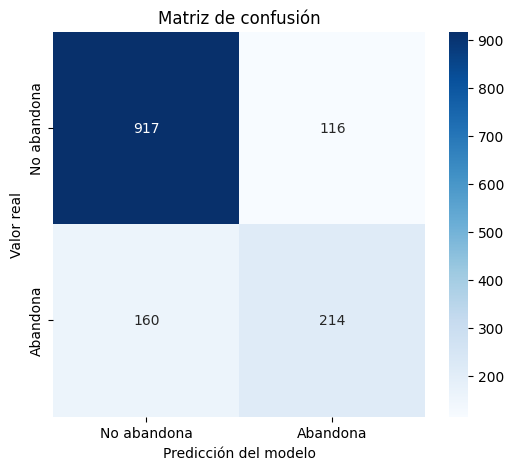

In [34]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No abandona",
        "Abandona"
    ],
    yticklabels=[
        "No abandona",
        "Abandona"
    ]
)

plt.title("Matriz de confusión")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")

plt.show()

In [35]:
tn, fp, fn, tp = matriz_confusion.ravel()

print("Verdaderos negativos (TN):", tn)
print("Falsos positivos (FP):", fp)
print("Falsos negativos (FN):", fn)
print("Verdaderos positivos (TP):", tp)

Verdaderos negativos (TN): 917
Falsos positivos (FP): 116
Falsos negativos (FN): 160
Verdaderos positivos (TP): 214


La matriz de confusión permite observar que el modelo no solamente debe ser evaluado por el número total de aciertos.

Resulta particularmente importante revisar los **falsos negativos**, debido a que corresponden a clientes que realmente pertenecían a la categoría de abandono pero fueron clasificados como clientes que permanecerían.

Si el modelo se utilizara como herramienta de apoyo para una estrategia de retención, estos clientes podrían no ser considerados para recibir atención preventiva.

Por este motivo, una posible mejora futura consistiría en aumentar la capacidad del modelo para identificar la clase positiva, aunque esto podría producir un incremento en los falsos positivos.

## 5.5 Curva ROC y área bajo la curva

Como evaluación adicional se utilizará la curva ROC.

Esta gráfica permite observar el comportamiento del clasificador con diferentes umbrales de decisión.

El área bajo la curva, conocida como **ROC-AUC**, proporciona una medida de la capacidad general del modelo para diferenciar entre las dos clases.

Un valor más cercano a 1 indica una mejor capacidad de separación, mientras que un valor alrededor de 0.5 representaría un comportamiento semejante a una clasificación aleatoria.

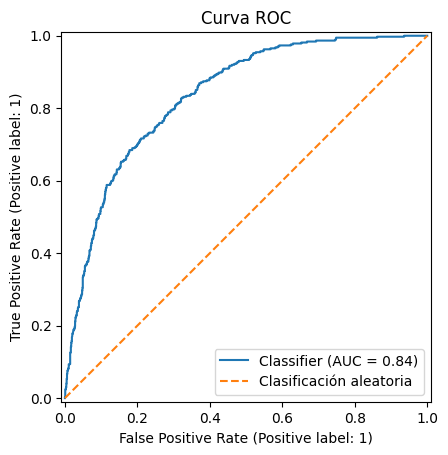

In [36]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificación aleatoria"
)

plt.title("Curva ROC")
plt.legend()

plt.show()

## 5.6 Resumen cuantitativo del desempeño

La siguiente celda mostrará una interpretación utilizando directamente los resultados obtenidos durante la ejecución del modelo.

In [37]:
print(
    "RESUMEN DEL MODELO\n"
)

print(
    f"El modelo clasificó correctamente "
    f"aproximadamente el {accuracy:.2%} "
    f"de los registros del conjunto de prueba."
)

print(
    f"Entre los clientes clasificados por el modelo "
    f"como abandono, el {precision:.2%} "
    f"realmente pertenecía a esa categoría."
)

print(
    f"De todos los clientes que realmente abandonaron, "
    f"el modelo logró identificar aproximadamente "
    f"el {recall:.2%}."
)

print(
    f"El F1-score obtenido fue de {f1:.4f}."
)

print(
    f"El área bajo la curva ROC fue de "
    f"{roc_auc:.4f}."
)

print(
    f"\nEn la matriz de confusión se obtuvieron:"
)

print(
    f"- {tn} verdaderos negativos."
)

print(
    f"- {fp} falsos positivos."
)

print(
    f"- {fn} falsos negativos."
)

print(
    f"- {tp} verdaderos positivos."
)

RESUMEN DEL MODELO

El modelo clasificó correctamente aproximadamente el 80.38% de los registros del conjunto de prueba.
Entre los clientes clasificados por el modelo como abandono, el 64.85% realmente pertenecía a esa categoría.
De todos los clientes que realmente abandonaron, el modelo logró identificar aproximadamente el 57.22%.
El F1-score obtenido fue de 0.6080.
El área bajo la curva ROC fue de 0.8359.

En la matriz de confusión se obtuvieron:
- 917 verdaderos negativos.
- 116 falsos positivos.
- 160 falsos negativos.
- 214 verdaderos positivos.


## 5.7 ¿El modelo cumple con el objetivo?

El modelo desarrollado permite realizar predicciones sobre clientes que no fueron utilizados durante su entrenamiento y genera tanto una clasificación como una probabilidad estimada de abandono.

Las métricas obtenidas permiten evaluar su desempeño desde diferentes perspectivas. El Accuracy muestra su capacidad general de clasificación, mientras que Precision, Recall y F1-score permiten analizar específicamente el comportamiento de la clase de abandono.

Por lo tanto, el modelo cumple con el objetivo académico planteado de construir una solución funcional de clasificación utilizando las cinco fases de CRISP-DM.

Sin embargo, esto no significa que el modelo se encuentre listo para utilizarse directamente en una empresa real. Para una aplicación de este tipo sería necesario realizar pruebas adicionales, utilizar información más reciente, comparar diferentes algoritmos y estudiar las consecuencias de los distintos tipos de error.

## 5.8 Limitaciones del modelo

Durante el desarrollo se identificaron algunas limitaciones que deben considerarse al interpretar los resultados.

**Desbalance de clases:** existen más clientes que permanecieron que clientes que abandonaron. Esto puede hacer que el modelo tenga mayor facilidad para aprender la clase mayoritaria.

**Datos históricos:** el modelo aprende exclusivamente de los patrones presentes en el conjunto de datos utilizado. Si el comportamiento de los clientes cambia, su desempeño también podría cambiar.

**Información disponible:** solamente pueden utilizarse las características incluidas en el conjunto de datos. Pueden existir otros factores relacionados con el abandono que no se encuentran registrados.

**Relación y no causalidad:** que una característica se encuentre asociada con una mayor probabilidad de abandono no significa que dicha característica sea necesariamente la causa del abandono.

**Errores de clasificación:** el modelo genera falsos positivos y falsos negativos. Por esta razón sus resultados no deben interpretarse como predicciones infalibles sobre el comportamiento de una persona.

## 5.9 Posibles mejoras

El proyecto podría mejorarse mediante diferentes estrategias:

- Comparar la Regresión Logística con otros algoritmos como Random Forest, K-Nearest Neighbors, Support Vector Machines o redes neuronales.
- Ajustar los hiperparámetros del modelo.
- Analizar diferentes umbrales de clasificación.
- Utilizar técnicas orientadas al tratamiento del desbalance de clases.
- Realizar validación cruzada.
- Estudiar cuáles variables tienen mayor influencia sobre las predicciones.
- Incorporar nuevas características de los clientes si estuvieran disponibles.
- Evaluar el modelo con información correspondiente a otros periodos de tiempo.

Estas mejoras permitirían determinar si es posible aumentar especialmente la capacidad de detectar clientes pertenecientes a la categoría de abandono.

# Conclusiones

El desarrollo de este proyecto permitió aplicar las cinco fases de trabajo de CRISP-DM para resolver un problema completo de clasificación utilizando Python y herramientas de aprendizaje automático.

Durante la **Comprensión del negocio** se definió el problema del abandono de clientes y se estableció `Churn` como la variable objetivo. Posteriormente, durante la **Comprensión de los datos**, se analizaron los 7,043 registros y 21 variables originales, identificando sus características, tipos de datos, distribución y algunos problemas de calidad.

La fase de **Preparación de los datos** permitió corregir la variable `TotalCharges`, identificar y eliminar los 11 registros que no contenían un valor válido, eliminar la variable `customerID`, transformar la variable objetivo y dividir el conjunto de datos en entrenamiento y prueba. También se estableció un proceso automático para codificar las variables categóricas y estandarizar las variables numéricas.

Durante la fase de **Modelado** se construyó un modelo de Regresión Logística mediante Scikit-learn. El preprocesamiento y el clasificador se integraron dentro de un Pipeline, permitiendo que las transformaciones necesarias se realizaran de manera consistente durante el entrenamiento y las predicciones.

Finalmente, en la fase de **Evaluación**, el modelo fue probado utilizando clientes que no participaron en su entrenamiento. Su funcionamiento se estudió mediante Accuracy, Precision, Recall, F1-score, ROC-AUC, un reporte de clasificación y una matriz de confusión.

Los resultados muestran que el modelo es capaz de aprender patrones presentes en las características de los clientes y utilizarlos para realizar una clasificación sobre nuevos registros. Sin embargo, la matriz de confusión demuestra también que existen errores, especialmente clientes pertenecientes a la categoría de abandono que pueden no ser identificados correctamente.

Este proyecto permitió comprender que el desarrollo de un modelo de Machine Learning no consiste únicamente en seleccionar un algoritmo y entrenarlo. La comprensión del problema, la exploración de los datos, su preparación y la selección adecuada de métricas son elementos fundamentales para poder interpretar correctamente los resultados.

Como trabajo futuro sería conveniente comparar la Regresión Logística con otros algoritmos, realizar ajustes de hiperparámetros y estudiar diferentes estrategias para mejorar la identificación de clientes pertenecientes a la clase de abandono.

# Referencias

- Blastchar. *Telco Customer Churn*. Kaggle. https://www.kaggle.com/datasets/blastchar/telco-customer-churn

- IBM. *Telco Customer Churn*. Conjunto de datos de ejemplo sobre abandono de clientes en telecomunicaciones.

- Pandas Development Team. *Pandas Documentation*.

- Scikit-learn Developers. *Scikit-learn User Guide*.

- Scikit-learn Developers. *LogisticRegression Documentation*.

- Scikit-learn Developers. *Preprocessing and Pipeline Documentation*.

- Matplotlib Development Team. *Matplotlib Documentation*.

- Seaborn Development Team. *Seaborn Documentation*.